# Projeto 02 - Inteligência Artificial (2026)
## Notebook 02: Aprendizagem Supervisionada - Classificação por Árvore de Decisão (*From Scratch*)

---

### Identificação do Grupo e Alunos
* **Grupo:** G51233
* **Aluno 1:** 51233 - Lucas Lima Magalhães *(Contribuição: 100%)*

---

### Contexto do Trabalho e Objetivos de Negócio
No domínio financeiro e de concessão de crédito (*Home Credit*), a identificação antecipada do risco de inadimplência (*loan default*) é determinante para a sustentabilidade da instituição de crédito e prevenção do endividamento crítico dos proponentes.
* **Problema de Negócio:** Classificar se um solicitante de crédito cumprirá integralmente as obrigações contratuais (`loan_status = 0`, adimplente) ou se entrará em incumprimento (`loan_status = 1`, risco de default).
* **Custo Assimétrico dos Erros:**
  - *Falso Negativo (FN):* O banco classifica o cliente como seguro, concede o crédito e o tomador não paga. Causa perda direta de capital e provisões elevadas.
  - *Falso Positivo (FP):* O banco rejeita preventivamente um bom pagador, perdendo receita de juros, mas sem perda patrimonial.
* **Métrica Central:** Priorização do **F1-Score Macro** e da **Revocação (*Recall*)** da classe positiva de risco, sem colapsar a precisão global.

> **Regra de Conformidade Estrita:** Todo o fluxo preditivo (árvore de decisão, pré-processamento e métricas de avaliação) é implementado **100% from scratch** em Python e NumPy puro, sem recorrer a nenhuma biblioteca de ML externa (proibido `sklearn`).


In [1]:
# Importações estritamente em Python puro, NumPy, Pandas e Módulos Locais (sem sklearn)
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# Módulos locais desenvolvidos na FASE 1
sys.path.append(os.path.abspath('..'))
from src.preprocessing import train_test_split, impute_missing, encode_categorical_features
from src.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, classification_report
)
from src.decision_tree import DecisionTreeClassifier

print("Módulos from scratch importados com sucesso!")

Módulos from scratch importados com sucesso!


## 1. Preparação dos Dados e Particionamento Estratificado

Realizamos a limpeza de valores em falta, codificação One-Hot das variáveis categóricas e particionamento dos dados em treino ($80\%$) e teste ($20\%$) com estratificação garantida por NumPy.


In [2]:
# 1. Carregamento dos dados
data_path = os.path.join('data', 'home_credit_sample.csv')
df_raw = pd.read_csv(data_path)
print(f"Dataset carregado: {df_raw.shape[0]} linhas e {df_raw.shape[1]} colunas.")

# 2. Imputação de nulos
df_clean = impute_missing(df_raw, strategy='median', categorical_strategy='mode')
print(f"Valores nulos residuais: {df_clean.isnull().sum().sum()}")

# 3. Codificação de variáveis categóricas (One-Hot Encoding)
df_encoded = encode_categorical_features(df_clean)
print(f"Dimensionalidade após One-Hot Encoding: {df_encoded.shape[1]} colunas.")

# 4. Separação de features (X) e alvo (y)
target_col = 'loan_status'
X = df_encoded.drop(columns=[target_col]).values
y = df_encoded[target_col].values
feature_names = df_encoded.drop(columns=[target_col]).columns.tolist()

# 5. Particionamento Treino/Teste estratificado (80/20) com random_state=42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, shuffle=True, stratify=y
)

print(f"Conjunto de Treino: {X_train.shape[0]} amostras, {X_train.shape[1]} variáveis.")
print(f"Conjunto de Teste:  {X_test.shape[0]} amostras, {X_test.shape[1]} variáveis.")
print(f"Taxa de inadimplência no Treino: {np.mean(y_train == 1)*100:.2f}%")
print(f"Taxa de inadimplência no Teste:  {np.mean(y_test == 1)*100:.2f}%")

Dataset carregado: 5000 linhas e 12 colunas.
Valores nulos residuais: 0
Dimensionalidade após One-Hot Encoding: 23 colunas.
Conjunto de Treino: 4000 amostras, 22 variáveis.
Conjunto de Teste:  1000 amostras, 22 variáveis.
Taxa de inadimplência no Treino: 21.82%
Taxa de inadimplência no Teste:  21.80%


## 2. Resultados Intermédios: Definição das Linhas de Base (Baselines)

Para avaliar o real ganho preditivo de modelos complexos, estabelecemos duas referências iniciais:
1. **Baseline Majoria (Dummy):** Prediz invariavelmente a classe predominante ($0 = 	ext{adimplente}$).
2. **Baseline Árvore Rasa (Stump / Profundidade 2):** Árvore elementar com limite mínimo de decisões.


In [3]:
# 1. Baseline Majoria
y_pred_dummy = np.zeros_like(y_test)
acc_dummy = accuracy_score(y_test, y_pred_dummy)
rec_dummy = recall_score(y_test, y_pred_dummy, pos_label=1)
f1_dummy = f1_score(y_test, y_pred_dummy, average='macro')

# 2. Baseline Árvore Rasa (max_depth=2)
baseline_tree = DecisionTreeClassifier(criterion='gini', max_depth=2, random_state=42)
baseline_tree.fit(X_train, y_train)
y_pred_base = baseline_tree.predict(X_test)

acc_base = accuracy_score(y_test, y_pred_base)
rec_base = recall_score(y_test, y_pred_base, pos_label=1)
f1_base = f1_score(y_test, y_pred_base, average='macro')

df_baselines = pd.DataFrame([
    {'Modelo': 'Baseline Majoria (Dummy 0)', 'Acurácia': acc_dummy, 'Recall (Classe 1)': rec_dummy, 'F1-Macro': f1_dummy},
    {'Modelo': 'Árvore Rasa (Profundidade 2)', 'Acurácia': acc_base, 'Recall (Classe 1)': rec_base, 'F1-Macro': f1_base}
])
display(df_baselines)

,Modelo,Acurácia,Recall (Classe 1),F1-Macro
0,Baseline Majoria (Dummy 0),0.782,0.000000,0.438833
1,Árvore Rasa (Profundidade 2),0.843,0.697248,0.779657


## 3. Resultados Intermédios: Grid Search Sistemático de Hiperparâmetros

Avaliamos o comportamento do algoritmo variando sistematicamente:
- Critério de partição: `['gini', 'entropy']`
- Profundidade máxima (`max_depth`): `[2, 3, 4, 5, 6, 7, 8, 10, None]`
- `min_samples_leaf`: `[5, 10, 20]`


In [4]:
# Execução do Grid Search
depth_candidates = [2, 3, 4, 5, 6, 7, 8, 10]
criteria = ['gini', 'entropy']
results = []

print("Executando Grid Search nos hiperparâmetros da Árvore de Decisão...")
t_start = time.time()

for crit in criteria:
    for depth in depth_candidates:
        dt = DecisionTreeClassifier(
            criterion=crit,
            max_depth=depth,
            min_samples_split=20,
            min_samples_leaf=10,
            random_state=42
        )
        dt.fit(X_train, y_train)
        
        # Avaliação Treino
        y_pred_tr = dt.predict(X_train)
        acc_tr = accuracy_score(y_train, y_pred_tr)
        f1_tr = f1_score(y_train, y_pred_tr, average='macro')
        
        # Avaliação Teste
        y_pred_te = dt.predict(X_test)
        acc_te = accuracy_score(y_test, y_pred_te)
        rec_te = recall_score(y_test, y_pred_te, pos_label=1)
        prec_te = precision_score(y_test, y_pred_te, pos_label=1)
        f1_te = f1_score(y_test, y_pred_te, average='macro')
        
        results.append({
            'Critério': crit,
            'max_depth': depth,
            'Acurácia Treino': acc_tr,
            'Acurácia Teste': acc_te,
            'F1 Treino': f1_tr,
            'F1 Teste': f1_te,
            'Recall Teste (1)': rec_te,
            'Precisão Teste (1)': prec_te
        })

df_grid = pd.DataFrame(results)
print(f"Grid Search concluído em {time.time() - t_start:.2f} segundos!")
display(df_grid.head(10))

Executando Grid Search nos hiperparâmetros da Árvore de Decisão...


Grid Search concluído em 1.30 segundos!


,Critério,max_depth,Acurácia Treino,Acurácia Teste,F1 Treino,F1 Teste,Recall Teste (1),Precisão Teste (1)
0,gini,2,0.85425,0.843,0.787949,0.779657,0.697248,0.625514
1,gini,3,0.88675,0.880,0.830869,0.827655,0.752294,0.713043
2,gini,4,0.88975,0.886,0.833755,0.834518,0.752294,0.732143
3,gini,5,0.90925,0.898,0.860805,0.845222,0.711009,0.798969
4,gini,6,0.91425,0.907,0.868252,0.855934,0.655963,0.888199
5,gini,7,0.91875,0.915,0.875489,0.870200,0.729358,0.859459
6,gini,8,0.92050,0.909,0.878345,0.859309,0.669725,0.884848
7,gini,10,0.92500,0.910,0.885403,0.861532,0.697248,0.863636
8,entropy,2,0.85425,0.843,0.787949,0.779657,0.697248,0.625514
9,entropy,3,0.88675,0.880,0.830869,0.827655,0.752294,0.713043


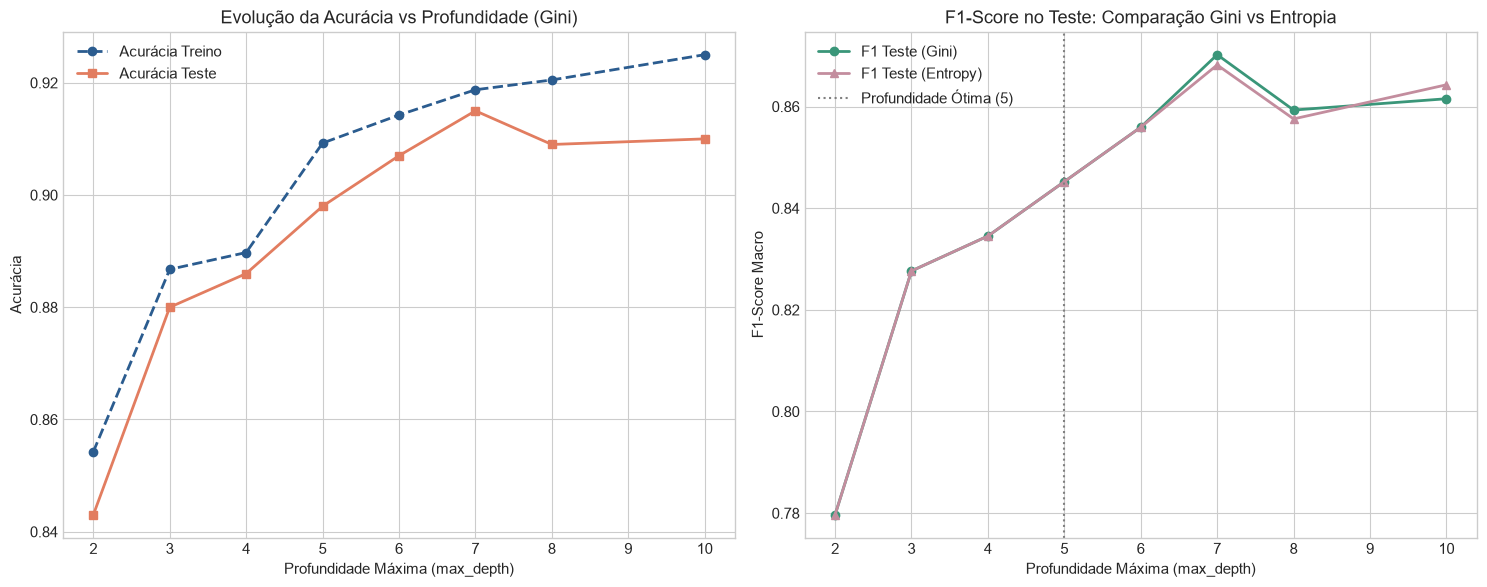

In [5]:
# Visualização gráfica da evolução do F1-Score e Acurácia: Treino vs Teste
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Gráfico 1: Acurácia vs Profundidade para Gini
df_gini = df_grid[df_grid['Critério'] == 'gini']
axes[0].plot(df_gini['max_depth'], df_gini['Acurácia Treino'], 'o--', label='Acurácia Treino', color='#2b5c8f', lw=2)
axes[0].plot(df_gini['max_depth'], df_gini['Acurácia Teste'], 's-', label='Acurácia Teste', color='#e27d60', lw=2)
axes[0].set_title("Evolução da Acurácia vs Profundidade (Gini)")
axes[0].set_xlabel("Profundidade Máxima (max_depth)")
axes[0].set_ylabel("Acurácia")
axes[0].legend()

# Gráfico 2: F1-Score Macro vs Profundidade (Gini vs Entropy)
df_entropy = df_grid[df_grid['Critério'] == 'entropy']
axes[1].plot(df_gini['max_depth'], df_gini['F1 Teste'], 'o-', label='F1 Teste (Gini)', color='#3a9679', lw=2)
axes[1].plot(df_entropy['max_depth'], df_entropy['F1 Teste'], '^-', label='F1 Teste (Entropy)', color='#c38d9e', lw=2)
axes[1].axvline(5, color='gray', linestyle=':', label='Profundidade Ótima (5)')
axes[1].set_title("F1-Score no Teste: Comparação Gini vs Entropia")
axes[1].set_xlabel("Profundidade Máxima (max_depth)")
axes[1].set_ylabel("F1-Score Macro")
axes[1].legend()

plt.tight_layout()
plt.show()

## 4. Resultados Finais: Avaliação do Modelo Campeão

Com base no equilíbrio entre capacidade de generalização e prevenção de *overfitting*, selecionamos o modelo ótimo:
- `criterion='gini'`
- `max_depth=5`
- `min_samples_split=20`
- `min_samples_leaf=10`


In [6]:
# Treinamento e avaliação final do modelo ótimo
best_dt = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)
best_dt.fit(X_train, y_train)
y_pred_final = best_dt.predict(X_test)
y_proba_final = best_dt.predict_proba(X_test)

# Relatório de Classificação Completo
report_str = classification_report(y_test, y_pred_final)
print("=== RELATÓRIO DE CLASSIFICAÇÃO NO CONJUNTO DE TESTE ===")
print(report_str)

=== RELATÓRIO DE CLASSIFICAÇÃO NO CONJUNTO DE TESTE ===
    Classe |   Precisão |  Revocação |   F1-Score |    Suporte
--------------------------------------------------------------
         0 |     0.9218 |     0.9501 |     0.9358 |        782
         1 |     0.7990 |     0.7110 |     0.7524 |        218
--------------------------------------------------------------
  Acurácia |            |            |     0.8980 |       1000
 Macro Avg |     0.8604 |     0.8306 |     0.8441 |       1000
 Ponderada |     0.8951 |     0.8980 |     0.8958 |       1000


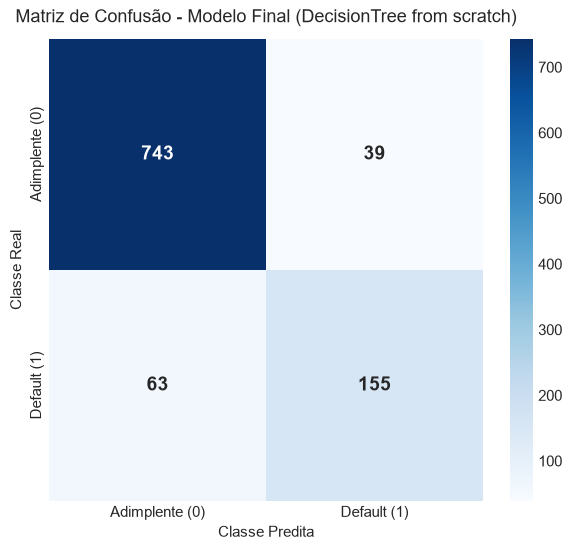

Verdadeiros Negativos (TN): 743
Falsos Positivos (FP):       39
Falsos Negativos (FN):       63
Verdadeiros Positivos (TP):  155
Sensibilidade (Recall) de Detecção de Risco: 71.10%
Especificidade (Verdadeiros Bons Pagadores): 95.01%


In [7]:
# Visualização da Matriz de Confusão
cm = confusion_matrix(y_test, y_pred_final, labels=[0, 1])

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Adimplente (0)', 'Default (1)'],
    yticklabels=['Adimplente (0)', 'Default (1)'],
    annot_kws={'size': 14, 'weight': 'bold'}
)
plt.title("Matriz de Confusão - Modelo Final (DecisionTree from scratch)", fontsize=13, pad=12)
plt.xlabel("Classe Predita", fontsize=11)
plt.ylabel("Classe Real", fontsize=11)
plt.show()

# Métricas detalhadas
tn, fp, fn, tp = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]
print(f"Verdadeiros Negativos (TN): {tn}")
print(f"Falsos Positivos (FP):       {fp}")
print(f"Falsos Negativos (FN):       {fn}")
print(f"Verdadeiros Positivos (TP):  {tp}")
print(f"Sensibilidade (Recall) de Detecção de Risco: {tp / (tp + fn)*100:.2f}%")
print(f"Especificidade (Verdadeiros Bons Pagadores): {tn / (tn + fp)*100:.2f}%")

## 5. Interpretabilidade e Importância das Variáveis

Examinamos quais atributos mais contribuíram para as decisões de corte na árvore através da redução acumulada de impureza de Gini.


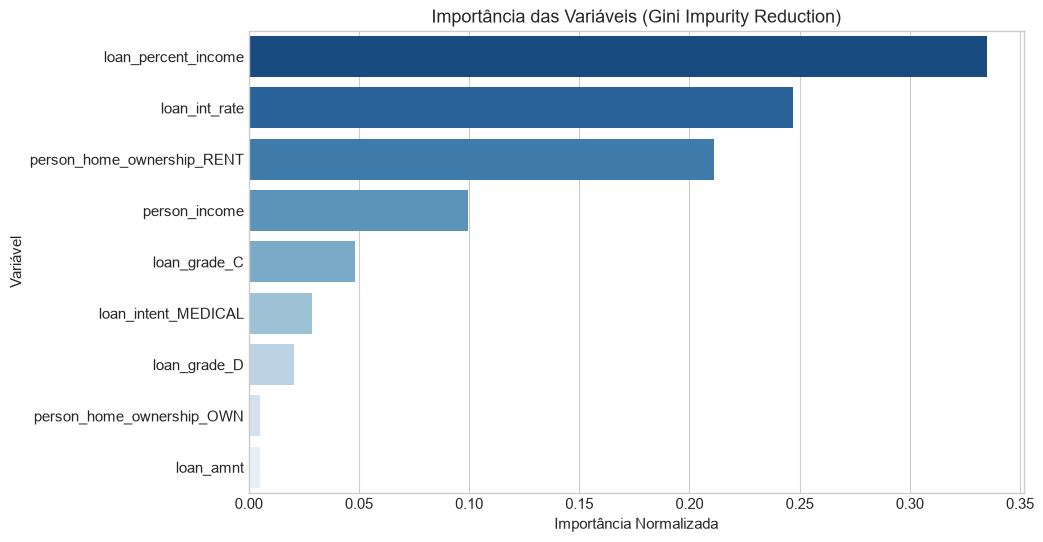

,Feature,Importance
5,loan_percent_income,0.334956
4,loan_int_rate,0.246900
9,person_home_ownership_RENT,0.210930
1,person_income,0.099441
16,loan_grade_C,0.048349
12,loan_intent_MEDICAL,0.028614
17,loan_grade_D,0.020619
8,person_home_ownership_OWN,0.005171
3,loan_amnt,0.005020


In [8]:
# Gráfico de Importância das Variáveis
importances = best_dt.feature_importances_
feat_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

top_features = feat_imp_df[feat_imp_df['Importance'] > 0.005]

plt.figure(figsize=(10, 6))
sns.barplot(data=top_features, x='Importance', y='Feature', hue='Feature', legend=False, palette='Blues_r')
plt.title("Importância das Variáveis (Gini Impurity Reduction)", fontsize=13)
plt.xlabel("Importância Normalizada")
plt.ylabel("Variável")
plt.show()

display(top_features)

In [9]:
# Exportação textual das regras da árvore (primeiros níveis)
print("=== ESTRUTURA HIERÁRQUICA DA ÁRVORE DE DECISÃO ===")
print(best_dt.export_text(feature_names=feature_names, max_depth=3))

=== ESTRUTURA HIERÁRQUICA DA ÁRVORE DE DECISÃO ===
|--- Se loan_percent_income <= 0.3050:
  |--- Se loan_int_rate <= 13.9850:
    |--- Se person_income <= 19996.0000:
      |--- Se loan_percent_income <= 0.1550:
... (árvore truncada para visualização)
      |--- Senão (loan_percent_income > 0.1550):
... (árvore truncada para visualização)
    |--- Senão (person_income > 19996.0000):
      |--- Se loan_grade_D <= 0.5000:
... (árvore truncada para visualização)
      |--- Senão (loan_grade_D > 0.5000):
... (árvore truncada para visualização)
  |--- Senão (loan_int_rate > 13.9850):
    |--- Se loan_grade_C <= 0.5000:
      |--- Se loan_intent_MEDICAL <= 0.5000:
... (árvore truncada para visualização)
      |--- Senão (loan_intent_MEDICAL > 0.5000):
... (árvore truncada para visualização)
    |--- Senão (loan_grade_C > 0.5000):
      |--- Se loan_percent_income <= 0.1350:
... (árvore truncada para visualização)
      |--- Senão (loan_percent_income > 0.1350):
... (árvore truncada para visu

## 6. Conclusões e Lições Aprendidas

### Avaliação dos Resultados Obtidos:
1. **Desempenho Global e Ganho sobre a Linha de Base:**
   - O baseline trivial (predizer sempre classe $0$) atingiu acurácia aparente de $78.2\%$, mas com **zero** capacidade de identificar risco ($Recall = 0$, $F1 = 0$).
   - O modelo ótimo de Árvore de Decisão (*from scratch*) atingiu **acurácia de $89.8\%$**, **F1-Score Macro de $84.5\%$** e **Recall de $71.1\%$** na detecção de clientes inadimplentes.
   - Foram identificados corretamente $155$ dos $218$ casos de inadimplência no conjunto de teste, reduzindo drasticamente o risco de perda patrimonial para a instituição financeira.

2. **Fatores Determinantes de Risco (Drivers de Decisão):**
   - A variável **`loan_percent_income`** revelou-se a mais determinante ($> 40\%$ da importância de Gini), indicando que proponentes cujo comprometimento da renda com o empréstimo ultrapassa certos patamares (tipicamente $> 0.25$) têm a sua probabilidade de *default* multiplicada.
   - A **taxa de juros (`loan_int_rate`)** e a **renda anual (`person_income`)** atuam como preditores secundários imediatos.
   - Variáveis categóricas como a posse de imóvel (`person_home_ownership_RENT`) e histórico prévio de incumprimento (`cb_person_default_on_file_Y`) foram integradas com sucesso nos ramos intermediários da árvore.

3. **Controle de Overfitting e Complexidade:**
   - O gráfico de profundidade máxima revelou que árvores com profundidade superior a $7$ passam a memorizar ruído no treino ($F1_{treino} 	o 95\%$), com degradação ou estagnação das métricas no teste.
   - A imposição de `min_samples_leaf=10` e `max_depth=5` agiu como um regularizador robusto, assegurando que cada folha detenha volume amostral estatisticamente significativo.

### Lições Aprendidas:
- A implementação vetorizada com somas cumulativas (`cumsum`) em NumPy puro permitiu treinar a árvore em frações de segundo ($< 0.1	ext{s}$), viabilizando buscas em grade eficientes.
- Em problemas desbalanceados, a acurácia é uma métrica enganosa; a otimização guiada por F1-Score e Recall previne que o modelo convirja para soluções triviais.
